# Group 06 — Rice Variety Classification: Proposed CNN + Attention
**Track 3: A custom CNN with CBAM channel and spatial attention**

The proposed network is a custom CNN designed for this project. It does not use ResNet18 as its feature-extraction backbone. CBAM is applied after the third convolutional block, before global average pooling and classification.

Two controlled experiments are trained: (1) the same custom CNN without attention and (2) the custom CNN with CBAM. This provides the initial Task 2 comparison for whether attention helps.

## 0. Install required packages

In [1]:
!pip -q install torch torchvision scikit-learn seaborn pandas matplotlib pillow

## 1. Imports and reproducibility

In [2]:
import os, zipfile, random, copy, json, time, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ImageFile.LOAD_TRUNCATED_IMAGES = False

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15                 # Increase to 25-30 for final experiments if time permits
LEARNING_RATE = 1e-3
PATIENCE = 5
NUM_WORKERS = 2

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.14.1+cu130


## 1. Dataset upload and extraction

Upload the same dataset ZIP used in Task 1. The code searches for `original_images/<class_name>/<image>` and deliberately excludes the pre-generated `augmented_images` folder. Training augmentation is applied online to training images only.

In [3]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No ZIP file was uploaded.")

ZIP_PATH = next(iter(uploaded))
EXTRACT_DIR = "/content/rice_dataset"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

print("Extracted:", ZIP_PATH)
print("Dataset root:", EXTRACT_DIR)

Saving PRBD Microscopic Image of Different Processed Rice.zip to PRBD Microscopic Image of Different Processed Rice.zip
Extracted: PRBD Microscopic Image of Different Processed Rice.zip
Dataset root: /content/rice_dataset


## 2. Read original images and validate the dataset

The dataset contains 10 rice varieties. This cell only accepts images located below an `original_images` directory. It verifies each image before adding it to the metadata table.

In [4]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
records = []

for path in Path(EXTRACT_DIR).rglob("*"):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTS:
        continue

    parts = path.parts
    lower_parts = [part.lower() for part in parts]

    if "original_images" not in lower_parts:
        continue

    original_idx = lower_parts.index("original_images")
    if original_idx + 1 >= len(parts) - 1:
        continue

    label = parts[original_idx + 1]

    try:
        with Image.open(path) as image:
            image.verify()
        records.append({"path": str(path), "label": label})
    except Exception as error:
        print("Skipped unreadable image:", path, "|", error)

data = (
    pd.DataFrame(records)
    .drop_duplicates(subset=["path"])
    .reset_index(drop=True)
)

if data.empty:
    raise ValueError(
        "No original images found. Expected folder structure: "
        "original_images/<class_name>/<image-file>. "
        "Check the ZIP folder structure."
    )

class_names = sorted(data["label"].unique().tolist())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}
data["label_id"] = data["label"].map(class_to_idx).astype(int)
NUM_CLASSES = len(class_names)

print("Original images:", len(data))
print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)
display(data.groupby("label").size().rename("image_count").reset_index())

if NUM_CLASSES != 10:
    print("WARNING: Expected 10 classes; found", NUM_CLASSES)

Original images: 2000
Number of classes: 10
Classes: ['Aush', 'BR-28', 'BR-29', 'Beroi', 'Chinigura', 'Ghee Bhog', 'Katari Najir', 'Katari Siddho', 'Miniket', 'Swarna']


,label,image_count
0,Aush,200
1,BR-28,200
2,BR-29,200
3,Beroi,200
4,Chinigura,200
5,Ghee Bhog,200
6,Katari Najir,200
7,Katari Siddho,200
8,Miniket,200
9,Swarna,200


## 3. Train / validation / test split (70/15/15)

Only original images are split. The same random seed and split procedure are used in both notebooks. No augmented copy is included in validation or test.

In [5]:
train_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    random_state=SEED,
    stratify=data["label_id"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label_id"]
)

for frame in (train_df, val_df, test_df):
    frame.reset_index(drop=True, inplace=True)

print(f"Train: {len(train_df)} ({len(train_df)/len(data):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(data):.1%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(data):.1%})")

split_summary = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
])
display(pd.crosstab(split_summary["label"], split_summary["split"]))

# Save exact split manifests for reproducibility.
SPLIT_DIR = "/content/rice_split_manifest"
os.makedirs(SPLIT_DIR, exist_ok=True)
train_df.to_csv(f"{SPLIT_DIR}/train.csv", index=False)
val_df.to_csv(f"{SPLIT_DIR}/validation.csv", index=False)
test_df.to_csv(f"{SPLIT_DIR}/test.csv", index=False)

Train: 1400 (70.0%)
Validation: 300 (15.0%)
Test: 300 (15.0%)


split,test,train,validation
label,,,
Aush,30,140,30
BR-28,30,140,30
BR-29,30,140,30
Beroi,30,140,30
Chinigura,30,140,30
Ghee Bhog,30,140,30
Katari Najir,30,140,30
Katari Siddho,30,140,30
Miniket,30,140,30


## 4. Preprocessing and DataLoaders

All images are resized to 224×224 and normalized using ImageNet channel statistics. Random augmentation is applied only to the training split.

In [6]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class RiceDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["path"]) as image:
            image = image.convert("RGB")
        image = self.transform(image)
        label = int(row["label_id"])
        return image, label

train_ds = RiceDataset(train_df, train_transform)
val_ds = RiceDataset(val_df, eval_transform)
test_ds = RiceDataset(test_df, eval_transform)

pin_memory = DEVICE.type == "cuda"
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=pin_memory
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory
)

images, labels = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))

Batch image shape: (32, 3, 224, 224)
Batch label shape: (32,)


## 5. Shared training, evaluation and model-size utilities

Best model weights are selected using validation loss. The held-out test set is evaluated only after training. Both macro and weighted metrics are reported.

In [7]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    y_true, y_pred = [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(logits.argmax(dim=1).detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(y_true, y_pred)
    return avg_loss, accuracy


def train_model(model, model_name, epochs=EPOCHS):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    start_time = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc = run_epoch(
            model, val_loader, criterion, optimizer=None
        )

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        current_lr = optimizer.param_groups[0]["lr"]
        print(
            f"{model_name} | Epoch {epoch+1}/{epochs} | "
            f"train loss={train_loss:.4f}, acc={train_acc:.4f} | "
            f"val loss={val_loss:.4f}, acc={val_acc:.4f} | "
            f"lr={current_lr:.2e}"
        )

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping triggered.")
            break

    training_seconds = time.time() - start_time
    model.load_state_dict(best_state)
    return model, history, training_seconds


def predict_all(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(DEVICE, non_blocking=True))
            y_pred.extend(logits.argmax(dim=1).cpu().numpy())
            y_true.extend(labels.numpy())

    return np.asarray(y_true), np.asarray(y_pred)


def evaluate_model(model, model_name, loader=test_loader, show_report=True):
    y_true, y_pred = predict_all(model, loader)

    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Precision_weighted": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall_weighted": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1_weighted": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

    if show_report:
        print("\\n", model_name)
        print(classification_report(
            y_true, y_pred,
            labels=list(range(NUM_CLASSES)),
            target_names=class_names,
            zero_division=0
        ))

        cm = confusion_matrix(
            y_true, y_pred, labels=list(range(NUM_CLASSES))
        )
        plt.figure(figsize=(9, 7))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names
        )
        plt.title(f"{model_name} - Confusion Matrix")
        plt.xlabel("Predicted label")
        plt.ylabel("True label")
        plt.xticks(rotation=45, ha="right")
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()

    return result


def model_information(model):
    total_params = sum(parameter.numel() for parameter in model.parameters())
    trainable_params = sum(
        parameter.numel() for parameter in model.parameters()
        if parameter.requires_grad
    )
    temp_path = "/content/_temporary_model_size.pth"
    torch.save(model.state_dict(), temp_path)
    model_size_mb = os.path.getsize(temp_path) / (1024 ** 2)
    os.remove(temp_path)

    return {
        "Parameters": total_params,
        "Trainable_parameters": trainable_params,
        "Model_size_MB": model_size_mb
    }


def plot_history(history, model_name):
    epochs_axis = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_axis, history["train_acc"], label="Train")
    plt.plot(epochs_axis, history["val_acc"], label="Validation")
    plt.title(model_name + " Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_axis, history["train_loss"], label="Train")
    plt.plot(epochs_axis, history["val_loss"], label="Validation")
    plt.title(model_name + " Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

## 6. CBAM attention module

In [8]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 1)
        self.shared_mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False)
        )

    def forward(self, x):
        avg_features = self.shared_mlp(F.adaptive_avg_pool2d(x, 1))
        max_features = self.shared_mlp(F.adaptive_max_pool2d(x, 1))
        attention = torch.sigmoid(avg_features + max_features)
        return x * attention


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(
            2, 1, kernel_size=kernel_size,
            padding=kernel_size // 2, bias=False
        )

    def forward(self, x):
        avg_map = torch.mean(x, dim=1, keepdim=True)
        max_map, _ = torch.max(x, dim=1, keepdim=True)
        combined = torch.cat([avg_map, max_map], dim=1)
        attention = torch.sigmoid(self.conv(combined))
        return x * attention


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.channel_attention = ChannelAttention(channels)
        self.spatial_attention = SpatialAttention(kernel_size=7)

    def forward(self, x):
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x

## 7. Proposed custom CNN architecture

Input 224×224×3 → Conv Block 1 (32 filters) → Conv Block 2 (64 filters) → Conv Block 3 (128 filters) → optional CBAM → Global Average Pooling → Dropout → 10-class output.

The `use_attention` flag creates an otherwise identical no-attention control model.

In [9]:
class CustomRiceCNN(nn.Module):
    def __init__(self, num_classes, use_attention=True):
        super().__init__()
        self.use_attention = use_attention

        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        if self.use_attention:
            self.attention = CBAM(128)

        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.40),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        if self.use_attention:
            x = self.attention(x)
        x = self.global_pool(x)
        return self.classifier(x)


proposed_model = CustomRiceCNN(NUM_CLASSES, use_attention=True)
test_output = proposed_model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE))
print(proposed_model)
print("Output tensor shape:", tuple(test_output.shape))
assert test_output.shape == (2, NUM_CLASSES)

CustomRiceCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (

## 8. Train controlled models: CNN without attention vs CNN + CBAM

\n========== CustomCNN_NoAttention ==========
CustomCNN_NoAttention | Epoch 1/15 | train loss=1.8628, acc=0.3657 | val loss=1.7473, acc=0.4200 | lr=1.00e-03
CustomCNN_NoAttention | Epoch 2/15 | train loss=1.5332, acc=0.4957 | val loss=1.4555, acc=0.5467 | lr=1.00e-03
CustomCNN_NoAttention | Epoch 3/15 | train loss=1.3941, acc=0.5521 | val loss=1.2746, acc=0.5900 | lr=1.00e-03
CustomCNN_NoAttention | Epoch 4/15 | train loss=1.3050, acc=0.5786 | val loss=1.1953, acc=0.6900 | lr=1.00e-03
CustomCNN_NoAttention | Epoch 5/15 | train loss=1.2137, acc=0.6171 | val loss=1.6830, acc=0.3567 | lr=1.00e-03
CustomCNN_NoAttention | Epoch 6/15 | train loss=1.1507, acc=0.6293 | val loss=1.1650, acc=0.6500 | lr=1.00e-03
CustomCNN_NoAttention | Epoch 7/15 | train loss=1.1286, acc=0.6214 | val loss=1.4199, acc=0.4367 | lr=1.00e-03
CustomCNN_NoAttention | Epoch 8/15 | train loss=1.0713, acc=0.6443 | val loss=1.2129, acc=0.4733 | lr=1.00e-03
CustomCNN_NoAttention | Epoch 9/15 | train loss=1.0628, acc=0.6436

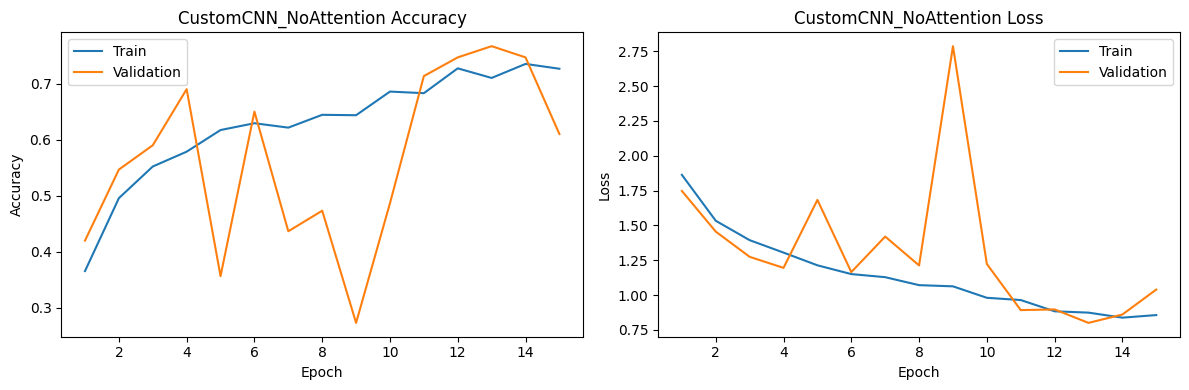

\n========== CustomCNN_CBAM ==========
CustomCNN_CBAM | Epoch 1/15 | train loss=1.9699, acc=0.2757 | val loss=1.9248, acc=0.1533 | lr=1.00e-03
CustomCNN_CBAM | Epoch 2/15 | train loss=1.5608, acc=0.4871 | val loss=1.4208, acc=0.4700 | lr=1.00e-03
CustomCNN_CBAM | Epoch 3/15 | train loss=1.3399, acc=0.5586 | val loss=1.4032, acc=0.4933 | lr=1.00e-03
CustomCNN_CBAM | Epoch 4/15 | train loss=1.2066, acc=0.6114 | val loss=1.2864, acc=0.5467 | lr=1.00e-03
CustomCNN_CBAM | Epoch 5/15 | train loss=1.0983, acc=0.6593 | val loss=1.2246, acc=0.5533 | lr=1.00e-03
CustomCNN_CBAM | Epoch 6/15 | train loss=0.9915, acc=0.6871 | val loss=0.9338, acc=0.7500 | lr=1.00e-03
CustomCNN_CBAM | Epoch 7/15 | train loss=0.9533, acc=0.6843 | val loss=0.8731, acc=0.6900 | lr=1.00e-03
CustomCNN_CBAM | Epoch 8/15 | train loss=0.9000, acc=0.6986 | val loss=1.0029, acc=0.6333 | lr=1.00e-03
CustomCNN_CBAM | Epoch 9/15 | train loss=0.8193, acc=0.7243 | val loss=0.7803, acc=0.7700 | lr=1.00e-03
CustomCNN_CBAM | Epoch 10

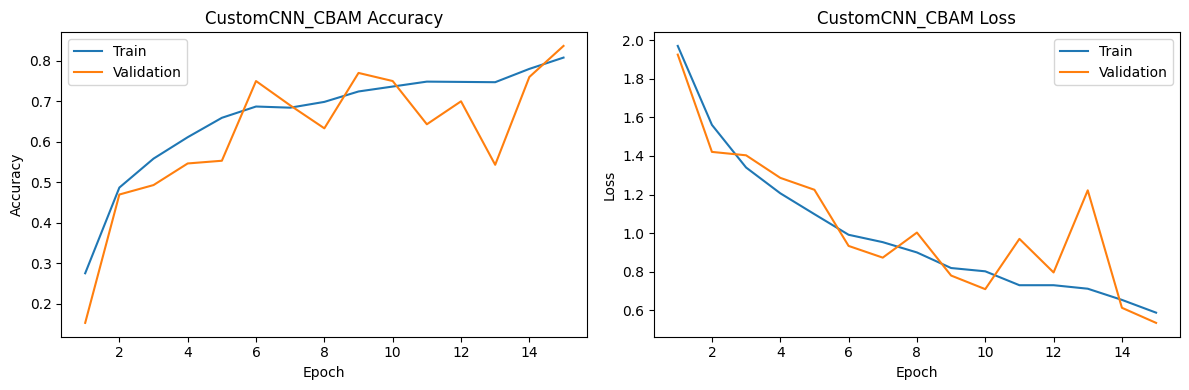

In [10]:
proposed_experiments = {
    "CustomCNN_NoAttention": CustomRiceCNN(NUM_CLASSES, use_attention=False),
    "CustomCNN_CBAM": CustomRiceCNN(NUM_CLASSES, use_attention=True)
}

proposed_models = {}
proposed_histories = {}
proposed_training_times = {}

for model_name, model in proposed_experiments.items():
    print("\\n==========", model_name, "==========")
    trained_model, history, training_seconds = train_model(model, model_name)
    proposed_models[model_name] = trained_model
    proposed_histories[model_name] = history
    proposed_training_times[model_name] = training_seconds
    plot_history(history, model_name)

## 9. Test evaluation and initial attention comparison

\n CustomCNN_NoAttention
               precision    recall  f1-score   support

         Aush       0.97      0.97      0.97        30
        BR-28       0.86      0.60      0.71        30
        BR-29       0.57      0.83      0.68        30
        Beroi       1.00      0.90      0.95        30
    Chinigura       1.00      0.63      0.78        30
    Ghee Bhog       0.71      0.83      0.77        30
 Katari Najir       0.60      1.00      0.75        30
Katari Siddho       1.00      0.17      0.29        30
      Miniket       0.85      0.97      0.91        30
       Swarna       0.71      0.83      0.77        30

     accuracy                           0.77       300
    macro avg       0.83      0.77      0.76       300
 weighted avg       0.83      0.77      0.76       300



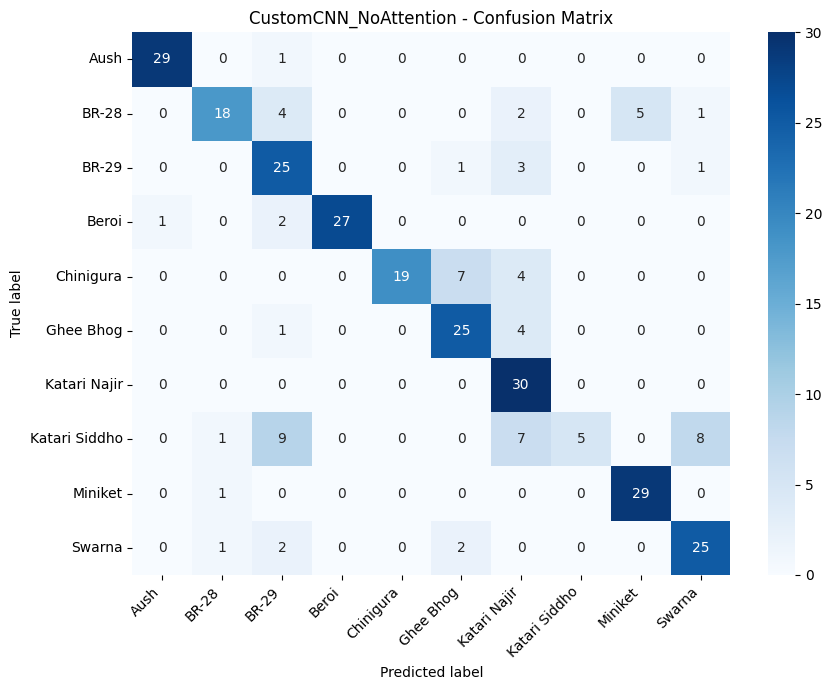

\n CustomCNN_CBAM
               precision    recall  f1-score   support

         Aush       0.94      0.97      0.95        30
        BR-28       0.81      0.83      0.82        30
        BR-29       0.96      0.73      0.83        30
        Beroi       0.96      0.90      0.93        30
    Chinigura       1.00      0.90      0.95        30
    Ghee Bhog       0.93      0.83      0.88        30
 Katari Najir       0.80      0.93      0.86        30
Katari Siddho       0.63      0.63      0.63        30
      Miniket       0.97      0.93      0.95        30
       Swarna       0.72      0.93      0.81        30

     accuracy                           0.86       300
    macro avg       0.87      0.86      0.86       300
 weighted avg       0.87      0.86      0.86       300



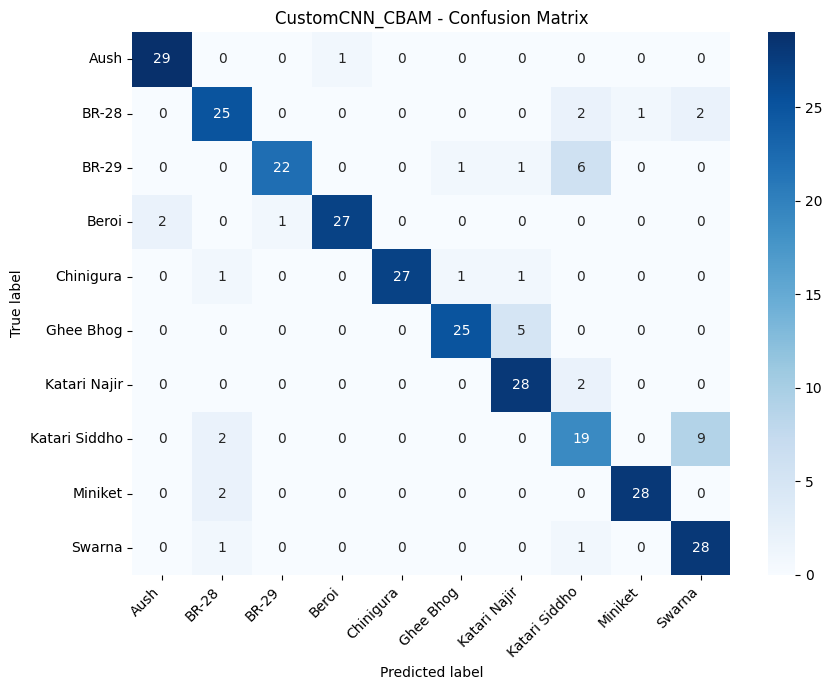

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_weighted,Recall_weighted,F1_weighted,Training_time_seconds,Parameters,Trainable_parameters,Model_size_MB
1,CustomCNN_CBAM,0.860000,0.870547,0.860000,0.861189,0.870547,0.860000,0.861189,314.844481,98956,98956,0.387928
0,CustomCNN_NoAttention,0.773333,0.827350,0.773333,0.755153,0.827350,0.773333,0.755153,306.389239,94762,94762,0.370563


CBAM minus no-attention:
Accuracy: +0.0867
Precision_macro: +0.0432
Recall_macro: +0.0867
F1_macro: +0.1060
F1_weighted: +0.1060


In [11]:
proposed_results = []

for model_name, model in proposed_models.items():
    metrics = evaluate_model(model, model_name)
    info = model_information(model)
    proposed_results.append({
        **metrics,
        "Training_time_seconds": proposed_training_times[model_name],
        **info
    })

proposed_results_df = pd.DataFrame(proposed_results)
display(proposed_results_df.sort_values("F1_macro", ascending=False))

comparison = proposed_results_df.set_index("Model")
no_att = comparison.loc["CustomCNN_NoAttention"]
with_cbam = comparison.loc["CustomCNN_CBAM"]

print("CBAM minus no-attention:")
for metric in ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro", "F1_weighted"]:
    print(f"{metric}: {with_cbam[metric] - no_att[metric]:+.4f}")

## 10. Grad-CAM explainability

Grad-CAM uses the last convolutional feature map (`block3[2]`) to visualize regions contributing to a selected class score. It is a visual explanation, not proof of causal reasoning. Examples include correct and incorrect predictions where available.

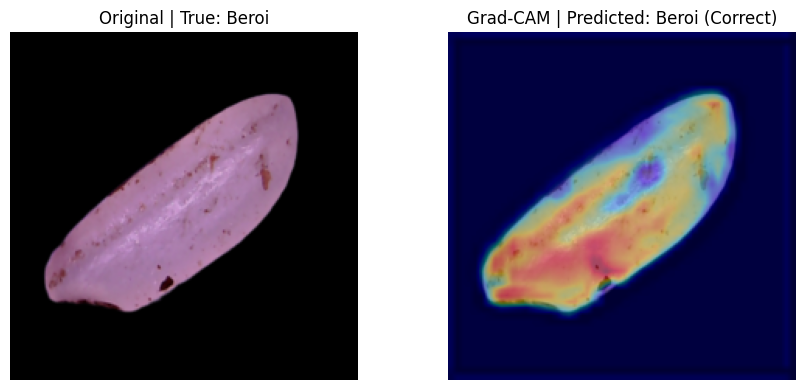

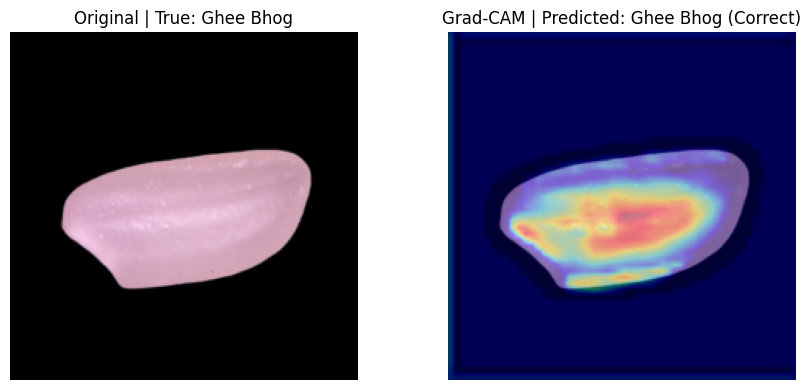

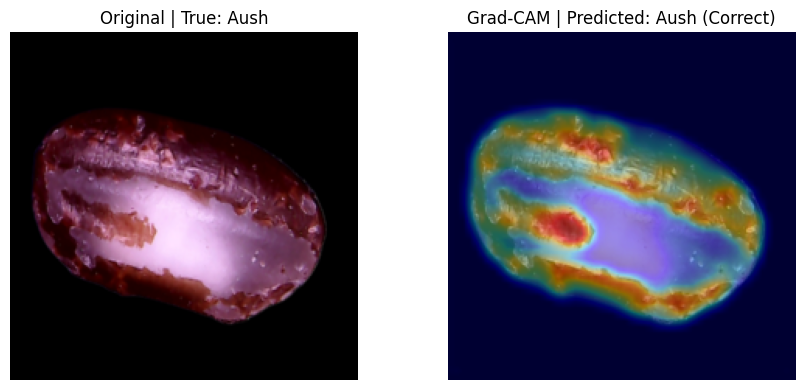

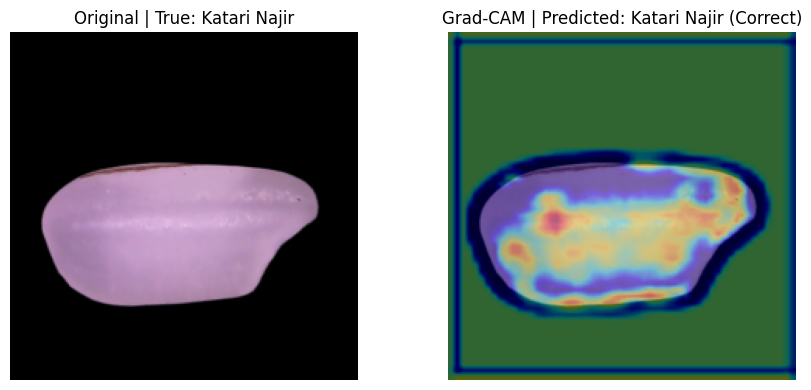

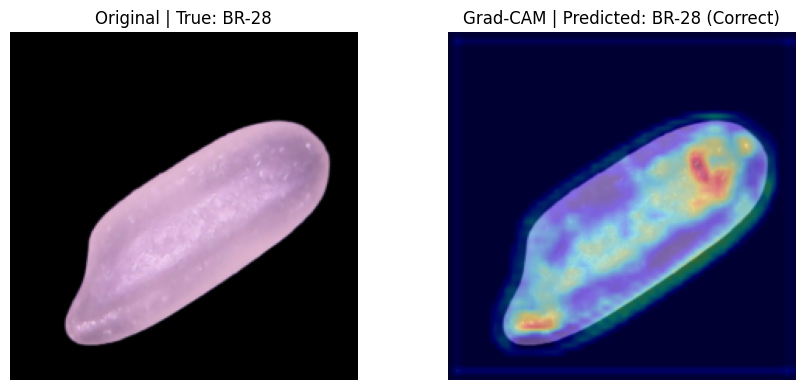

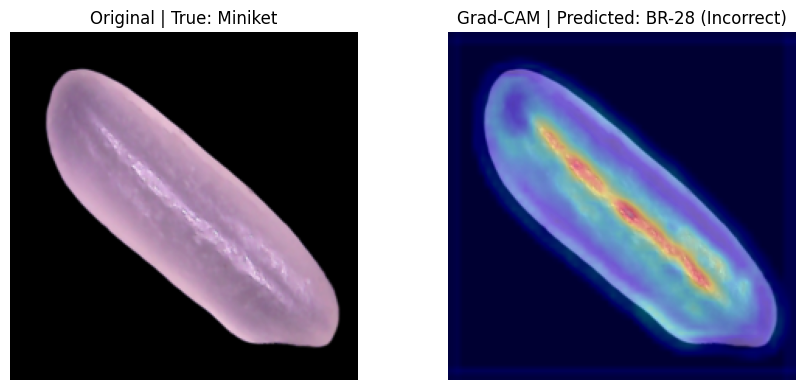

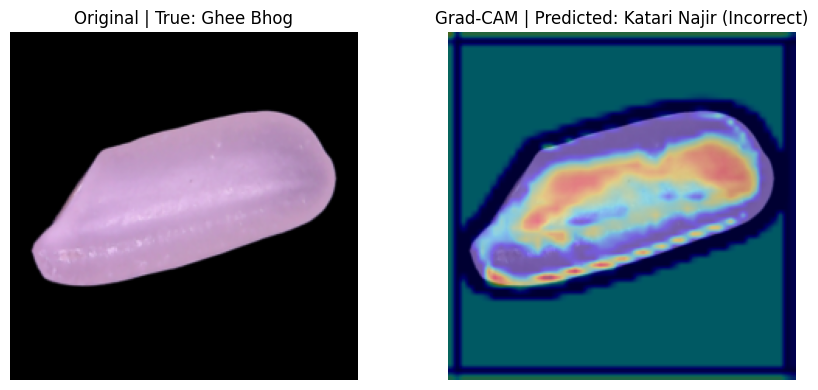

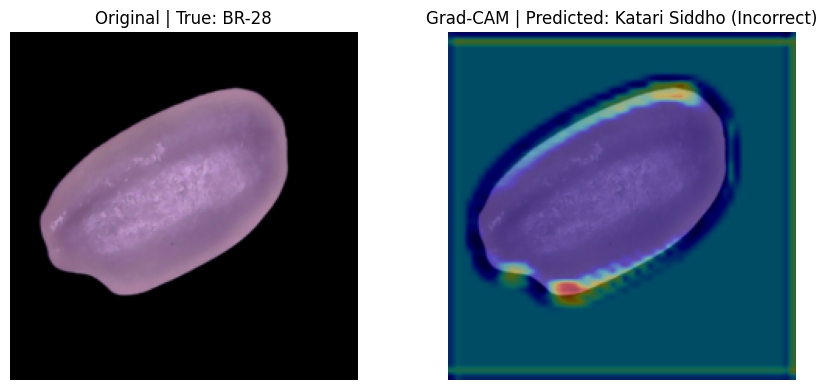

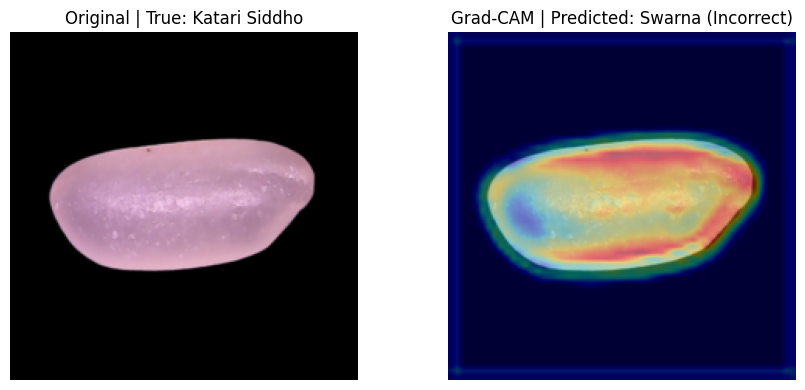

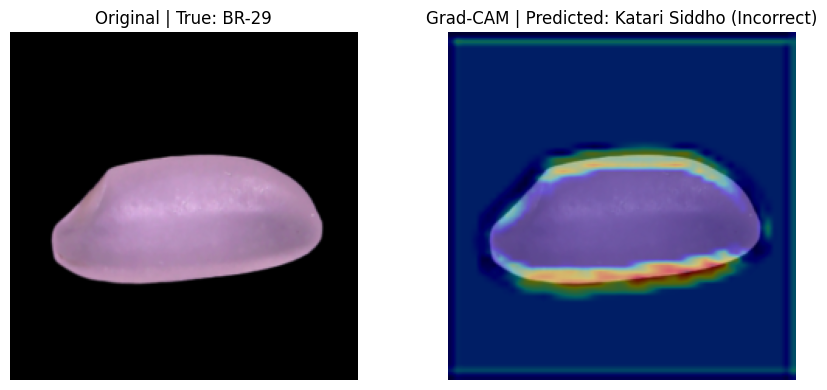

In [12]:
def make_gradcam(model, image_tensor, target_class=None):
    model.eval()
    activations, gradients = [], []
    target_layer = model.block3[2]

    def forward_hook(module, inputs, output):
        activations.append(output)
        output.register_hook(lambda grad: gradients.append(grad.detach()))

    hook = target_layer.register_forward_hook(forward_hook)
    model.zero_grad(set_to_none=True)
    image_batch = image_tensor.unsqueeze(0).to(DEVICE)

    logits = model(image_batch)
    predicted_class = int(logits.argmax(dim=1).item())
    if target_class is None:
        target_class = predicted_class

    logits[0, target_class].backward()
    hook.remove()

    activation = activations[0].detach()
    gradient = gradients[0]
    weights = gradient.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * activation).sum(dim=1, keepdim=True))
    cam = F.interpolate(
        cam, size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear", align_corners=False
    )[0, 0]

    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    return predicted_class, cam.cpu().numpy()


def denormalize_image(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    image = tensor.cpu() * std + mean
    return np.clip(image.permute(1, 2, 0).numpy(), 0, 1)


def show_gradcam_examples(model, dataset, max_examples=10):
    model.eval()
    correct_indices, incorrect_indices = [], []

    for index in range(len(dataset)):
        image_tensor, true_label = dataset[index]
        with torch.no_grad():
            predicted = int(
                model(image_tensor.unsqueeze(0).to(DEVICE))
                .argmax(dim=1).item()
            )
        if predicted == true_label:
            correct_indices.append(index)
        else:
            incorrect_indices.append(index)

    selected = correct_indices[:max_examples // 2]
    selected += incorrect_indices[:max_examples - len(selected)]

    if not selected:
        print("No test examples available.")
        return

    for index in selected:
        image_tensor, true_label = dataset[index]
        predicted, cam = make_gradcam(model, image_tensor)
        image = denormalize_image(image_tensor)
        status = "Correct" if predicted == true_label else "Incorrect"

        plt.figure(figsize=(9, 4))
        plt.subplot(1, 2, 1)
        plt.imshow(image)
        plt.title("Original | True: " + class_names[true_label])
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(image)
        plt.imshow(cam, cmap="jet", alpha=0.40)
        plt.title(f"Grad-CAM | Predicted: {class_names[predicted]} ({status})")
        plt.axis("off")
        plt.tight_layout()
        plt.show()


cbam_model = proposed_models["CustomCNN_CBAM"]
show_gradcam_examples(cbam_model, test_ds, max_examples=10)

## 11. Save models, metrics, label map and split manifests

In [13]:
OUTPUT_DIR = "/content/task2_proposed_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

proposed_results_df.to_csv(
    f"{OUTPUT_DIR}/proposed_model_results.csv", index=False
)
with open(f"{OUTPUT_DIR}/label_map.json", "w") as file:
    json.dump(class_to_idx, file, indent=2)

for model_name, model in proposed_models.items():
    torch.save(model.state_dict(), f"{OUTPUT_DIR}/{model_name.lower()}.pth")

for split_name, frame in [
    ("train", train_df), ("validation", val_df), ("test", test_df)
]:
    frame.to_csv(f"{OUTPUT_DIR}/{split_name}_split.csv", index=False)

with open(f"{OUTPUT_DIR}/experiment_config.json", "w") as file:
    json.dump({
        "architecture": "Custom CNN with optional CBAM",
        "attention": "CBAM: channel attention followed by spatial attention",
        "attention_placement": "after third convolutional block, before global average pooling",
        "seed": SEED,
        "image_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "max_epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "split": "70/15/15 stratified; original images only",
        "classes": class_names
    }, file, indent=2)

print("Saved outputs to:", OUTPUT_DIR)

Saved outputs to: /content/task2_proposed_outputs


## 12. Download proposed model outputs

In [14]:
shutil.make_archive(
    "/content/Group06_RiceVarities_task2_proposed_outputs",
    "zip",
    OUTPUT_DIR
)
from google.colab import files
files.download("/content/Group06_RiceVarities_task2_proposed_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>